In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip -q install torch-fidelity scikit-image tqdm

In [ ]:
import json, random
from pathlib import Path

import numpy as np
import torch
from torch.utils.data import ConcatDataset, DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

SEED = 42

DATASET = "FashionMNIST"
BATCH_SIZE = 128
NUM_WORKERS = 2

TRAIN_RATIO, VAL_RATIO, TEST_RATIO = 0.80, 0.10, 0.10

DATA_ROOT = Path("/content/data")
DRIVE_ROOT = Path("/content/drive/MyDrive/DL_Sesi07")
CKPT_DIR = DRIVE_ROOT / "checkpoints"
FIG_DIR = DRIVE_ROOT / "figures"
RESULT_DIR = DRIVE_ROOT / "results"
SPLIT_FILE = RESULT_DIR / f"split_indices_{DATASET}_seed{SEED}.json"

In [ ]:
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def get_device():
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def ensure_dirs(*dirs):
    for d in dirs:
        Path(d).mkdir(parents=True, exist_ok=True)


def save_json(obj, path):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w") as f:
        json.dump(obj, f, indent=2)


def load_json(path):
    with open(path) as f:
        return json.load(f)


def save_checkpoint(path, model, optimizer, epoch, history=None, extra=None):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    torch.save({
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict() if optimizer is not None else None,
        "epoch": epoch,
        "history": history or {},
        "extra": extra or {},
    }, path)


def load_checkpoint(path, model, optimizer=None, map_location=None):
    ckpt = torch.load(path, map_location=map_location)
    model.load_state_dict(ckpt["model"])
    if optimizer is not None and ckpt.get("optimizer") is not None:
        optimizer.load_state_dict(ckpt["optimizer"])
    return ckpt["epoch"], ckpt.get("history", {}), ckpt.get("extra", {})

In [ ]:
_DATASETS = {
    "FashionMNIST": datasets.FashionMNIST,
    "MNIST": datasets.MNIST,
    "KMNIST": datasets.KMNIST,
    "CIFAR10": datasets.CIFAR10,
}


def get_full_dataset(name=DATASET, root=DATA_ROOT):
    cls = _DATASETS[name]
    tf = transforms.ToTensor()
    train = cls(root=str(root), train=True, download=True, transform=tf)
    test = cls(root=str(root), train=False, download=True, transform=tf)
    return ConcatDataset([train, test])


def make_split_indices(n, seed=SEED, train_ratio=TRAIN_RATIO, val_ratio=VAL_RATIO):
    rng = np.random.RandomState(seed)
    perm = rng.permutation(n)
    n_train = int(n * train_ratio)
    n_val = int(n * val_ratio)
    return {
        "train": perm[:n_train].tolist(),
        "val": perm[n_train:n_train + n_val].tolist(),
        "test": perm[n_train + n_val:].tolist(),
    }


def get_split_indices(n, split_file=SPLIT_FILE):
    try:
        idx = load_json(split_file)
        print(f"[split] dimuat dari {split_file}")
    except FileNotFoundError:
        idx = make_split_indices(n)
        save_json(idx, split_file)
        print(f"[split] dibuat baru dan disimpan ke {split_file}")
    return idx


def get_datasets(name=DATASET):
    full = get_full_dataset(name)
    idx = get_split_indices(len(full))
    return {k: Subset(full, v) for k, v in idx.items()}


def get_loaders(batch_size=BATCH_SIZE, name=DATASET):
    ds = get_datasets(name)
    g = torch.Generator()
    g.manual_seed(SEED)
    return {
        "train": DataLoader(ds["train"], batch_size=batch_size, shuffle=True, num_workers=NUM_WORKERS, generator=g),
        "val": DataLoader(ds["val"], batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS),
        "test": DataLoader(ds["test"], batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS),
    }


def to_minus1_1(x):
    return x * 2.0 - 1.0


def from_minus1_1(x):
    return ((x + 1.0) / 2.0).clamp(0.0, 1.0)

In [ ]:
set_seed(SEED)
device = get_device()
ensure_dirs(CKPT_DIR, FIG_DIR, RESULT_DIR)
print("Device:", device)
print("Dataset:", DATASET, "| Seed:", SEED, "| Batch:", BATCH_SIZE)

Device: cuda
Dataset: FashionMNIST | Seed: 42 | Batch: 128


In [ ]:
ds = get_datasets()
print({k: len(v) for k, v in ds.items()})

loaders = get_loaders()
x, y = next(iter(loaders['train']))
print("Batch:", x.shape, y.shape, "| min/max:", x.min().item(), x.max().item())

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.5MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 173kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.20MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 8.90MB/s]


[split] dibuat baru dan disimpan ke /content/drive/MyDrive/DL_Sesi07/results/split_indices_FashionMNIST_seed42.json
{'train': 56000, 'val': 7000, 'test': 7000}
[split] dimuat dari /content/drive/MyDrive/DL_Sesi07/results/split_indices_FashionMNIST_seed42.json
Batch: torch.Size([128, 1, 28, 28]) torch.Size([128]) | min/max: 0.0 1.0


In [ ]:
idx = load_json(SPLIT_FILE)
s_tr, s_va, s_te = set(idx['train']), set(idx['val']), set(idx['test'])
print(f"train={len(s_tr)} val={len(s_va)} test={len(s_te)} total={len(s_tr)+len(s_va)+len(s_te)}")

train=56000 val=7000 test=7000 total=70000


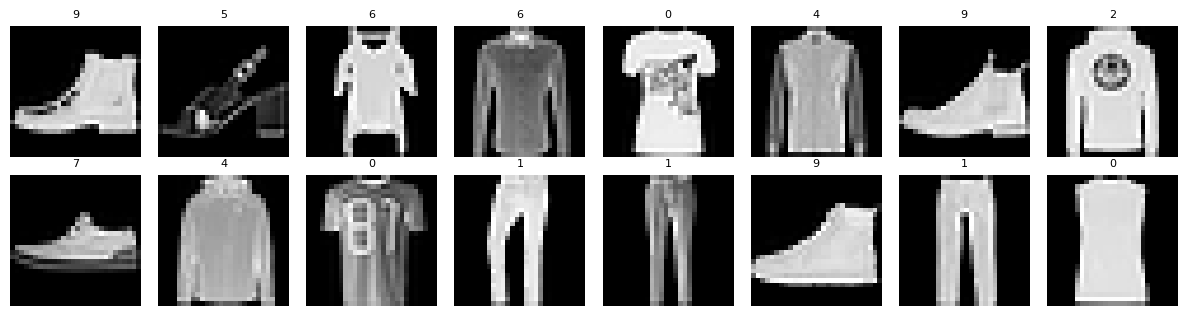

In [ ]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for i, ax in enumerate(axes.flat):
    img = x[i].squeeze().cpu().numpy() if x[i].shape[0] == 1 else x[i].permute(1, 2, 0).cpu().numpy()
    ax.imshow(img, cmap='gray' if x[i].shape[0] == 1 else None)
    ax.set_title(int(y[i]), fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
import time
import torch.nn as nn
import torch.nn.functional as F
from skimage.metrics import structural_similarity as sk_ssim

_x0, _ = next(iter(loaders['train']))
IMG_SHAPE = tuple(_x0.shape[1:])
IN_DIM = int(np.prod(IMG_SHAPE))

def flat(x):
    return x.reshape(x.size(0), -1)

@torch.no_grad()
def evaluate_recon(recon_fn, loader):
    mses, psnrs, ssims = [], [], []
    for x, _ in loader:
        x = x.to(device)
        xh = recon_fn(x).clamp(0, 1)
        mse = ((xh - flat(x)) ** 2).mean(1)
        mses.append(mse.cpu())
        psnrs.append((10 * torch.log10(1.0 / mse.clamp_min(1e-10))).cpu())
        a = x.cpu().numpy()
        b = xh.reshape(x.shape).cpu().numpy()
        for i in range(a.shape[0]):
            if IMG_SHAPE[0] == 1:
                ssims.append(sk_ssim(a[i, 0], b[i, 0], data_range=1.0))
            else:
                ssims.append(sk_ssim(a[i], b[i], data_range=1.0, channel_axis=0))
    return {"mse": torch.cat(mses).mean().item(),
            "psnr": torch.cat(psnrs).mean().item(),
            "ssim": float(np.mean(ssims))}

In [ ]:
class MLPClassifier(nn.Module):
    def __init__(self, in_dim=IN_DIM, h1=256, z_dim=64, n_cls=10):
        super().__init__()
        self.fc1 = nn.Linear(in_dim, h1)
        self.fc2 = nn.Linear(h1, z_dim)
        self.fc3 = nn.Linear(z_dim, n_cls)

    def features(self, x):
        h1 = F.relu(self.fc1(flat(x)))
        return F.relu(self.fc2(h1))

    def forward(self, x):
        return self.fc3(self.features(x))


@torch.no_grad()
def accuracy(model, loader):
    model.eval()
    correct = n = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        correct += (model(x).argmax(1) == y).sum().item()
        n += y.size(0)
    return correct / n


set_seed(SEED)
mlp = MLPClassifier().to(device)
opt = torch.optim.Adam(mlp.parameters(), lr=1e-3)
EPOCHS_MLP = 30
hist_mlp = {"train_loss": [], "val_acc": []}
best_val, best_state = 0.0, None

for ep in range(1, EPOCHS_MLP + 1):
    mlp.train()
    tot = n = 0
    for x, y in loaders['train']:
        x, y = x.to(device), y.to(device)
        loss = F.cross_entropy(mlp(x), y)
        opt.zero_grad(); loss.backward(); opt.step()
        tot += loss.item() * y.size(0); n += y.size(0)
    va = accuracy(mlp, loaders['val'])
    hist_mlp["train_loss"].append(tot / n); hist_mlp["val_acc"].append(va)
    if va > best_val:
        best_val = va
        best_state = {k: v.clone() for k, v in mlp.state_dict().items()}
    print(f"Epoch {ep:02d} | loss {tot/n:.4f} | val acc {va:.4f}")

mlp.load_state_dict(best_state)
test_acc = accuracy(mlp, loaders['test'])
print(f"\nTEST ACCURACY: {test_acc:.4f}")
save_checkpoint(CKPT_DIR / "mlp_classifier.pt", mlp, opt, EPOCHS_MLP, hist_mlp)
save_json(hist_mlp, RESULT_DIR / "mlp_classifier_history.json")

Epoch 01 | loss 0.6045 | val acc 0.8370
Epoch 02 | loss 0.4169 | val acc 0.8609
Epoch 03 | loss 0.3669 | val acc 0.8646
Epoch 04 | loss 0.3366 | val acc 0.8750
Epoch 05 | loss 0.3166 | val acc 0.8749
Epoch 06 | loss 0.2973 | val acc 0.8796
Epoch 07 | loss 0.2856 | val acc 0.8804
Epoch 08 | loss 0.2751 | val acc 0.8791
Epoch 09 | loss 0.2614 | val acc 0.8847
Epoch 10 | loss 0.2538 | val acc 0.8916
Epoch 11 | loss 0.2436 | val acc 0.8924
Epoch 12 | loss 0.2361 | val acc 0.8946
Epoch 13 | loss 0.2271 | val acc 0.8851
Epoch 14 | loss 0.2209 | val acc 0.8947
Epoch 15 | loss 0.2111 | val acc 0.8953
Epoch 16 | loss 0.2057 | val acc 0.8961
Epoch 17 | loss 0.2010 | val acc 0.8991
Epoch 18 | loss 0.1932 | val acc 0.8984
Epoch 19 | loss 0.1866 | val acc 0.8949
Epoch 20 | loss 0.1823 | val acc 0.8966
Epoch 21 | loss 0.1753 | val acc 0.8980
Epoch 22 | loss 0.1718 | val acc 0.9006
Epoch 23 | loss 0.1679 | val acc 0.8986
Epoch 24 | loss 0.1615 | val acc 0.9001
Epoch 25 | loss 0.1542 | val acc 0.8991


In [ ]:
for p in mlp.parameters():
    p.requires_grad = False
mlp.eval()

W1, W2, W3 = mlp.fc1.weight.detach(), mlp.fc2.weight.detach(), mlp.fc3.weight.detach()

def orth_error(W):
    G = W @ W.T
    I = torch.eye(G.size(0), device=W.device)
    return ((G - I).norm() / I.norm()).item()

for name, W in [("W1", W1), ("W2", W2), ("W3", W3)]:
    S = torch.linalg.svdvals(W)
    print(f"{name} {tuple(W.shape)} | ||WW^T - I||_F/||I||_F = {orth_error(W):.3f} | rank maks = {min(W.shape)} (dimensi input {W.shape[1]}) | cond = {(S.max()/S.min()).item():.1f}")

with torch.no_grad():
    xb, _ = next(iter(loaders['test']))
    xb = xb.to(device)
    a1 = mlp.fc1(flat(xb)); a2 = mlp.fc2(F.relu(a1))
    print(f"\nFraksi unit dipotong ReLU: layer1 = {(a1 <= 0).float().mean():.3f} layer2 (z_MLP) = {(a2 <= 0).float().mean():.3f}")

W1 (256, 784) | ||WW^T - I||_F/||I||_F = 34.888 | rank maks = 256 (dimensi input 784) | cond = 42.1
W2 (64, 256) | ||WW^T - I||_F/||I||_F = 10.624 | rank maks = 64 (dimensi input 256) | cond = 17.9
W3 (10, 64) | ||WW^T - I||_F/||I||_F = 4.735 | rank maks = 10 (dimensi input 64) | cond = 2.7

Fraksi unit dipotong ReLU: layer1 = 0.748 layer2 (z_MLP) = 0.511


In [ ]:
@torch.no_grad()
def backproject_from_class():
    n_cls = W3.size(0)
    Y = torch.eye(n_cls, device=device)
    z_hat = F.relu(Y @ W3)
    h1_hat = F.relu(z_hat @ W2)
    return torch.sigmoid(h1_hat @ W1)

xhat_cls = backproject_from_class()

class_means = torch.zeros(W3.size(0), IN_DIM, device=device)
counts = torch.zeros(W3.size(0), device=device)
for x, y in loaders['test']:
    x, y = x.to(device), y.to(device)
    for c in range(W3.size(0)):
        m = (y == c)
        class_means[c] += flat(x)[m].sum(0); counts[c] += m.sum()
class_means /= counts.unsqueeze(1)

print("MSE(x_hat vs rata-rata kelas):", F.mse_loss(xhat_cls, class_means).item())
print("Std piksel x_hat (rendah = bercak datar):", xhat_cls.std(1).mean().item())
print("Std piksel rata-rata kelas asli       :", class_means.std(1).mean().item())

MSE(x_hat vs rata-rata kelas): 0.11378875374794006
Std piksel x_hat (rendah = bercak datar): 0.1498904526233673
Std piksel rata-rata kelas asli       : 0.25228187441825867


In [ ]:
@torch.no_grad()
def backproject_from_latent(z):
    return torch.sigmoid(F.relu(z @ W2) @ W1)

res_stage3 = evaluate_recon(lambda x: backproject_from_latent(mlp.features(x)), loaders['test'])
print("Tahap 3 (W^T dari z_MLP) pada test set:", res_stage3)

Tahap 3 (W^T dari z_MLP) pada test set: {'mse': 0.30585289001464844, 'psnr': 5.198549747467041, 'ssim': 0.05505660687923361}


In [ ]:
class MLPDecoder(nn.Module):
    def __init__(self, z_dim=64, h=256, out_dim=IN_DIM):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(z_dim, h), nn.ReLU(), nn.Linear(h, out_dim), nn.Sigmoid())
    def forward(self, z):
        return self.net(z)


class FrozenLatentRecon(nn.Module):
    def __init__(self, mlp, z_dim=64):
        super().__init__()
        self.mlp = mlp
        self.dec = MLPDecoder(z_dim)
    def train(self, mode=True):
        super().train(mode)
        self.mlp.eval()
        return self
    def forward(self, x):
        with torch.no_grad():
            z = self.mlp.features(x)
        return self.dec(z)


class VanillaAE(nn.Module):
    def __init__(self, in_dim=IN_DIM, h=256, z_dim=64):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(in_dim, h), nn.ReLU(), nn.Linear(h, z_dim))
        self.dec = nn.Sequential(nn.Linear(z_dim, h), nn.ReLU(), nn.Linear(h, in_dim), nn.Sigmoid())
    def encode(self, x):
        return self.enc(flat(x))
    def forward(self, x):
        return self.dec(self.encode(x))


def fit_recon(model, epochs=30, lr=1e-3, ckpt_name=None):
    model.to(device)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.Adam(params, lr=lr)
    hist = {"train_loss": [], "val_loss": [], "epoch_time": []}
    best_val, best_state = float("inf"), None
    for ep in range(1, epochs + 1):
        t0 = time.time(); model.train(); tot = n = 0
        for x, _ in loaders['train']:
            x = x.to(device)
            loss = F.mse_loss(model(x), flat(x))
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * x.size(0); n += x.size(0)
        model.eval(); vt = vn = 0
        with torch.no_grad():
            for x, _ in loaders['val']:
                x = x.to(device)
                vt += F.mse_loss(model(x), flat(x), reduction='sum').item() / IN_DIM
                vn += x.size(0)
        if device.type == "cuda":
            torch.cuda.synchronize()
        hist["train_loss"].append(tot / n); hist["val_loss"].append(vt / vn)
        hist["epoch_time"].append(time.time() - t0)
        if vt / vn < best_val:
            best_val = vt / vn
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        print(f"Epoch {ep:02d} | train {tot/n:.5f} | val {vt/vn:.5f} | {hist['epoch_time'][-1]:.1f}s")
    model.load_state_dict(best_state)
    if ckpt_name:
        save_checkpoint(CKPT_DIR / f"{ckpt_name}.pt", model, opt, epochs, hist)
        save_json(hist, RESULT_DIR / f"{ckpt_name}_history.json")
    return hist


EPOCHS_REC = 30

print("Frozen latent decoder")
set_seed(SEED)
frozen_model = FrozenLatentRecon(mlp)
hist_frozen = fit_recon(frozen_model, EPOCHS_REC, ckpt_name="frozen_latent_decoder")

print("\nVanilla AE (latent 64)")
set_seed(SEED)
vae64 = VanillaAE()
hist_vae64 = fit_recon(vae64, EPOCHS_REC, ckpt_name="vanilla_ae_z64")

frozen_model.eval(); vae64.eval()
res_frozen = evaluate_recon(lambda x: frozen_model(x), loaders['test'])
res_ae = evaluate_recon(lambda x: vae64(x), loaders['test'])

print("\nTest set: z_MLP vs z_AE, latent 64")
print(f"{'Model':<28}{'MSE':>10}{'PSNR (dB)':>12}{'SSIM':>9}")
for name, r in [("Frozen z_MLP + Decoder", res_frozen), ("Vanilla AE (z_AE)", res_ae)]:
    print(f"{name:<28}{r['mse']:>10.5f}{r['psnr']:>12.2f}{r['ssim']:>9.4f}")

Frozen latent decoder
Epoch 01 | train 0.03634 | val 0.02746 | 7.3s
Epoch 02 | train 0.02493 | val 0.02407 | 8.9s
Epoch 03 | train 0.02273 | val 0.02270 | 7.2s
Epoch 04 | train 0.02152 | val 0.02145 | 8.7s
Epoch 05 | train 0.02072 | val 0.02074 | 14.2s
Epoch 06 | train 0.02015 | val 0.02068 | 11.2s
Epoch 07 | train 0.01974 | val 0.02007 | 8.7s
Epoch 08 | train 0.01935 | val 0.01993 | 8.4s
Epoch 09 | train 0.01909 | val 0.01950 | 7.3s
Epoch 10 | train 0.01883 | val 0.01923 | 8.4s
Epoch 11 | train 0.01864 | val 0.01910 | 7.4s
Epoch 12 | train 0.01848 | val 0.01887 | 8.4s
Epoch 13 | train 0.01828 | val 0.01878 | 8.3s
Epoch 14 | train 0.01817 | val 0.01871 | 7.7s
Epoch 15 | train 0.01806 | val 0.01859 | 8.5s
Epoch 16 | train 0.01797 | val 0.01856 | 7.4s
Epoch 17 | train 0.01785 | val 0.01847 | 8.5s
Epoch 18 | train 0.01776 | val 0.01843 | 7.0s
Epoch 19 | train 0.01767 | val 0.01828 | 8.5s
Epoch 20 | train 0.01763 | val 0.01824 | 7.0s
Epoch 21 | train 0.01755 | val 0.01808 | 9.2s
Epoch 22 |

In [ ]:
@torch.no_grad()
def collect_latents(loader):
    return torch.cat([mlp.features(x.to(device)) for x, _ in loader])

Z_test = collect_latents(loaders['test'])
mu_z, sigma_z = Z_test.mean(0), Z_test.std(0)

set_seed(SEED)
z_rand = mu_z + sigma_z * torch.randn(16, Z_test.size(1), device=device)
with torch.no_grad():
    x_rand = frozen_model.dec(z_rand)

print(f"Fraksi komponen z_rand bernilai negatif: {(z_rand < 0).float().mean():.3f} (z_MLP asli hasil ReLU selalu >= 0)")
print(f"Fraksi komponen z_MLP asli yang bernilai 0 : {(Z_test == 0).float().mean():.3f}")

Fraksi komponen z_rand bernilai negatif: 0.206 (z_MLP asli hasil ReLU selalu >= 0)
Fraksi komponen z_MLP asli yang bernilai 0 : 0.515


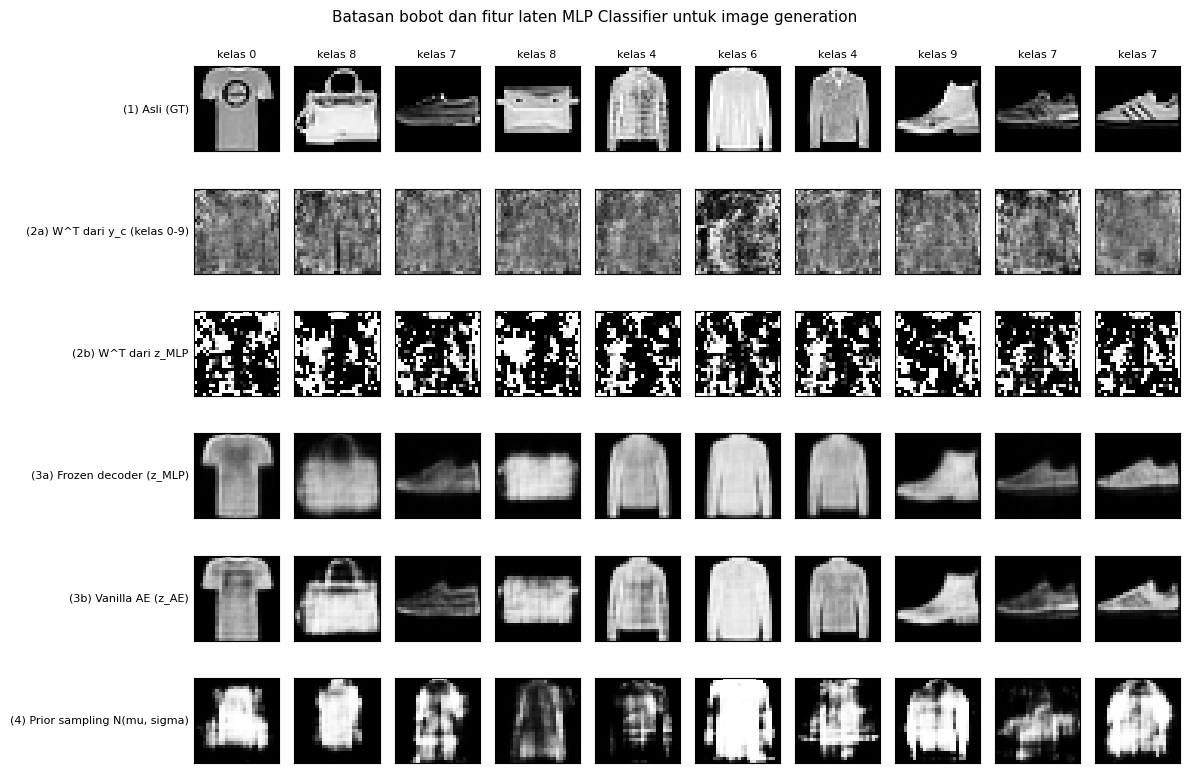

In [ ]:
def to_img(t):
    return t.reshape(-1, *IMG_SHAPE).cpu()

def show_row(axes, imgs, ylabel):
    for j, ax in enumerate(axes):
        im = imgs[j]
        im = im[0] if IMG_SHAPE[0] == 1 else im.permute(1, 2, 0)
        ax.imshow(im.numpy(), cmap='gray' if IMG_SHAPE[0] == 1 else None, vmin=0, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
    axes[0].set_ylabel(ylabel, rotation=0, ha='right', va='center', fontsize=8)

x10, y10 = next(iter(loaders['test']))
x10, y10 = x10[:10].to(device), y10[:10]

with torch.no_grad():
    z10 = mlp.features(x10)
    rows = [
        ("(1) Asli (GT)", x10),
        ("(2a) W^T dari y_c (kelas 0-9)", xhat_cls[:10]),
        ("(2b) W^T dari z_MLP", backproject_from_latent(z10)),
        ("(3a) Frozen decoder (z_MLP)", frozen_model(x10)),
        ("(3b) Vanilla AE (z_AE)", vae64(x10)),
        ("(4) Prior sampling N(mu, sigma)", x_rand[:10]),
    ]

fig, axes = plt.subplots(len(rows), 10, figsize=(12, 8))
for r, (label, imgs) in enumerate(rows):
    show_row(axes[r], to_img(imgs), label)
for j in range(10):
    axes[0][j].set_title(f"kelas {int(y10[j])}", fontsize=8)
fig.suptitle("Batasan bobot dan fitur laten MLP Classifier untuk image generation", fontsize=11)
plt.tight_layout()
fig.savefig(FIG_DIR / "fig3_mlp_classifier_limits.png", dpi=200, bbox_inches='tight')
plt.show()

In [ ]:
save_json({
    "mlp_test_acc": test_acc,
    "stage3_W_transpose_from_z": res_stage3,
    "stage4_frozen_latent_decoder": res_frozen,
    "stage4_vanilla_ae_z64": res_ae,
    "orth_error": {n: orth_error(W) for n, W in [("W1", W1), ("W2", W2), ("W3", W3)]},
}, RESULT_DIR / "mlp_proof_metrics.json")
print("Tersimpan di:", RESULT_DIR / "mlp_proof_metrics.json")

Tersimpan di: /content/drive/MyDrive/DL_Sesi07/results/mlp_proof_metrics.json


In [ ]:
ae = vae64

class SparseAE(nn.Module):
    def __init__(self, in_dim=IN_DIM, h=256, z_dim=64):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(in_dim, h), nn.ReLU(), nn.Linear(h, z_dim), nn.ReLU())
        self.dec = nn.Sequential(nn.Linear(z_dim, h), nn.ReLU(), nn.Linear(h, in_dim), nn.Sigmoid())
    def encode(self, x):
        return self.enc(flat(x))
    def forward(self, x):
        return self.dec(self.encode(x))


class VAE(nn.Module):
    def __init__(self, in_dim=IN_DIM, h=256, z_dim=64):
        super().__init__()
        self.z_dim = z_dim
        self.body = nn.Sequential(nn.Linear(in_dim, h), nn.ReLU())
        self.fc_mu = nn.Linear(h, z_dim)
        self.fc_logvar = nn.Linear(h, z_dim)
        self.dec = nn.Sequential(nn.Linear(z_dim, h), nn.ReLU(), nn.Linear(h, in_dim), nn.Sigmoid())
    def encode(self, x):
        hh = self.body(flat(x))
        return self.fc_mu(hh), self.fc_logvar(hh)
    def reparam(self, mu, logvar):
        return mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)
    def decode(self, z):
        return self.dec(z)
    def forward(self, x):
        mu, logvar = self.encode(x)
        return self.decode(self.reparam(mu, logvar)), mu, logvar


def make_sparse_loss(lam):
    def loss_fn(model, x):
        z = model.encode(x)
        xh = model.dec(z)
        rec = F.mse_loss(xh, flat(x))
        l1 = lam * z.abs().sum(1).mean()
        return rec + l1, {"recon": rec.item(), "l1": l1.item()}
    return loss_fn


def vae_loss(model, x):
    xh, mu, logvar = model(x)
    rec = F.binary_cross_entropy(xh, flat(x), reduction='sum') / x.size(0)
    kl = (-0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).sum(1)).mean()
    return rec + kl, {"recon": rec.item(), "kl": kl.item()}


def fit_generic(model, loss_fn, epochs=30, lr=1e-3, ckpt_name=None, verbose=True):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "val_loss": [], "epoch_time": []}
    best_val, best_state = float("inf"), None
    for ep in range(1, epochs + 1):
        t0 = time.time(); model.train(); tot = n = 0
        comp_sum = {}
        for x, _ in loaders['train']:
            x = x.to(device)
            loss, comps = loss_fn(model, x)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * x.size(0); n += x.size(0)
            for k, v in comps.items():
                comp_sum[k] = comp_sum.get(k, 0.0) + v * x.size(0)
        model.eval(); vt = vn = 0
        with torch.no_grad():
            for x, _ in loaders['val']:
                x = x.to(device)
                l, _ = loss_fn(model, x)
                vt += l.item() * x.size(0); vn += x.size(0)
        if device.type == "cuda":
            torch.cuda.synchronize()
        hist["train_loss"].append(tot / n); hist["val_loss"].append(vt / vn)
        hist["epoch_time"].append(time.time() - t0)
        for k, v in comp_sum.items():
            hist.setdefault(f"train_{k}", []).append(v / n)
        if vt / vn < best_val:
            best_val = vt / vn
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        if verbose:
            comps_txt = " ".join(f"{k}={v/n:.4f}" for k, v in comp_sum.items())
            print(f"Epoch {ep:02d} | train {tot/n:.5f} | val {vt/vn:.5f} | {comps_txt} | {hist['epoch_time'][-1]:.1f}s")
    model.load_state_dict(best_state)
    if ckpt_name:
        save_checkpoint(CKPT_DIR / f"{ckpt_name}.pt", model, opt, epochs, hist)
        save_json(hist, RESULT_DIR / f"{ckpt_name}_history.json")
    return hist

In [ ]:
LAMBDA_SPARSE = 1e-4
EPOCHS_AE = 30

set_seed(SEED)
sparse_ae = SparseAE()
hist_sparse = fit_generic(sparse_ae, make_sparse_loss(LAMBDA_SPARSE), epochs=EPOCHS_AE, ckpt_name="sparse_ae_z64")

Epoch 01 | train 0.03724 | val 0.02226 | recon=0.0346 l1=0.0026 | 10.8s
Epoch 02 | train 0.01981 | val 0.01849 | recon=0.0180 l1=0.0018 | 8.1s
Epoch 03 | train 0.01722 | val 0.01665 | recon=0.0157 l1=0.0016 | 10.9s
Epoch 04 | train 0.01572 | val 0.01547 | recon=0.0142 l1=0.0015 | 10.5s
Epoch 05 | train 0.01473 | val 0.01456 | recon=0.0133 l1=0.0014 | 9.4s
Epoch 06 | train 0.01401 | val 0.01423 | recon=0.0126 l1=0.0014 | 12.1s
Epoch 07 | train 0.01345 | val 0.01353 | recon=0.0121 l1=0.0013 | 8.4s
Epoch 08 | train 0.01300 | val 0.01321 | recon=0.0117 l1=0.0013 | 12.1s
Epoch 09 | train 0.01260 | val 0.01277 | recon=0.0114 l1=0.0013 | 10.8s
Epoch 10 | train 0.01228 | val 0.01246 | recon=0.0111 l1=0.0012 | 8.9s
Epoch 11 | train 0.01200 | val 0.01227 | recon=0.0108 l1=0.0012 | 12.4s
Epoch 12 | train 0.01175 | val 0.01198 | recon=0.0106 l1=0.0011 | 12.0s
Epoch 13 | train 0.01154 | val 0.01176 | recon=0.0104 l1=0.0011 | 10.2s
Epoch 14 | train 0.01133 | val 0.01170 | recon=0.0102 l1=0.0011 | 8.

In [ ]:
set_seed(SEED)
vae = VAE()
hist_vae = fit_generic(vae, vae_loss, epochs=EPOCHS_AE, ckpt_name="vae_z64")

Epoch 01 | train 300.87267 | val 275.56065 | recon=286.3291 kl=14.5436 | 9.0s
Epoch 02 | train 267.50411 | val 264.41851 | recon=250.9371 kl=16.5670 | 7.8s
Epoch 03 | train 258.34179 | val 257.46170 | recon=242.6697 kl=15.6721 | 9.0s
Epoch 04 | train 253.14478 | val 253.35597 | recon=238.0007 kl=15.1441 | 8.5s
Epoch 05 | train 250.08183 | val 251.25715 | recon=235.0311 kl=15.0507 | 8.0s
Epoch 06 | train 248.10350 | val 249.40705 | recon=233.0010 kl=15.1025 | 9.1s
Epoch 07 | train 246.80250 | val 248.55519 | recon=231.5785 kl=15.2240 | 7.6s
Epoch 08 | train 245.81389 | val 247.64644 | recon=230.5032 kl=15.3107 | 9.1s
Epoch 09 | train 244.95629 | val 246.85906 | recon=229.5733 kl=15.3830 | 8.1s
Epoch 10 | train 244.35951 | val 246.55266 | recon=228.9231 kl=15.4364 | 8.8s
Epoch 11 | train 243.90418 | val 245.79117 | recon=228.3806 kl=15.5235 | 9.1s
Epoch 12 | train 243.50579 | val 246.17366 | recon=227.9342 kl=15.5715 | 7.7s
Epoch 13 | train 243.17124 | val 245.13563 | recon=227.5541 kl=1

In [24]:
ae.eval()
sparse_ae.eval()
vae.eval()

res_ae = evaluate_recon(lambda x: ae(x), loaders['test'])
res_sp = evaluate_recon(lambda x: sparse_ae(x), loaders['test'])
res_vae = evaluate_recon(lambda x: vae.decode(vae.encode(x)[0]), loaders['test'])

print(f"{'Model':<14}{'MSE':>10}{'PSNR (dB)':>12}{'SSIM':>9}{'s/epoch':>10}")
for name, r, h in [("Vanilla AE", res_ae, hist_vae64), ("Sparse AE", res_sp, hist_sparse), ("VAE", res_vae, hist_vae)]:
    print(f"{name:<14}{r['mse']:>10.5f}{r['psnr']:>12.2f}{r['ssim']:>9.4f}{np.mean(h['epoch_time']):>10.2f}")

@torch.no_grad()
def code_stats(encode_fn, loader, eps=1e-2):
    Z = torch.cat([encode_fn(x.to(device)) for x, _ in loader])
    return {"mean_abs": Z.abs().mean().item(),
            "frac_near_zero": (Z.abs() < eps).float().mean().item(),
            "frac_dead_units": (Z.abs().max(0).values < eps).float().mean().item()}

stats_ae = code_stats(ae.encode, loaders['test'])
stats_sp = code_stats(sparse_ae.encode, loaders['test'])
stats_vae = code_stats(lambda x: vae.encode(x)[0], loaders['test'])
print("\nStatistik kode laten (|z| < 0.01 dianggap nol):")
for name, s in [("Vanilla AE", stats_ae), ("Sparse AE", stats_sp), ("VAE (mu)", stats_vae)]:
    print(f"{name:<12} mean|z|={s['mean_abs']:.3f} | frac~0={s['frac_near_zero']:.3f} | unit mati={s['frac_dead_units']:.3f}")

Model                MSE   PSNR (dB)     SSIM   s/epoch
Vanilla AE       0.00653       23.01   0.8289      8.08
Sparse AE        0.00920       21.40   0.7718      9.25
VAE              0.01298       19.73   0.7138      8.50

Statistik kode laten (|z| < 0.01 dianggap nol):
Vanilla AE   mean|z|=1.193 | frac~0=0.006 | unit mati=0.000
Sparse AE    mean|z|=0.124 | frac~0=0.508 | unit mati=0.453
VAE (mu)     mean|z|=0.171 | frac~0=0.167 | unit mati=0.000


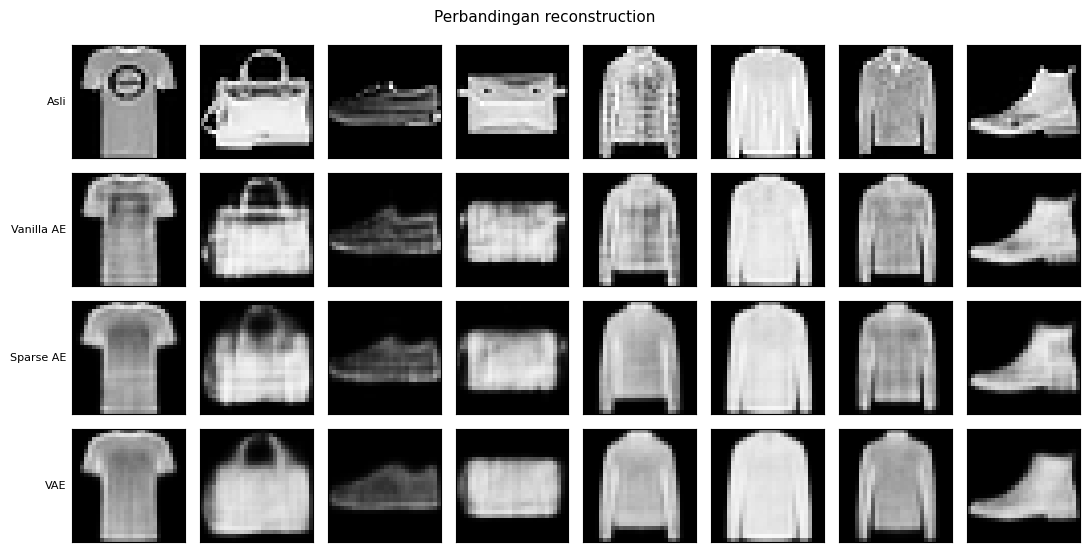

In [25]:
xs, ys = next(iter(loaders['test']))
xs = xs[:8].to(device)

with torch.no_grad():
    rows = [("Asli", xs),
            ("Vanilla AE", ae(xs)),
            ("Sparse AE", sparse_ae(xs)),
            ("VAE", vae.decode(vae.encode(xs)[0]))]

fig, axes = plt.subplots(len(rows), 8, figsize=(11, 5.6))
for r, (label, imgs) in enumerate(rows):
    show_row(axes[r], to_img(imgs), label)
fig.suptitle("Perbandingan reconstruction", fontsize=11)
plt.tight_layout()
fig.savefig(FIG_DIR / "fig1_reconstruction.png", dpi=200, bbox_inches='tight')
plt.show()

In [26]:
rows_sweep = []
for lam in [0.0, 1e-5, 1e-4, 1e-3, 1e-2]:
    set_seed(SEED)
    m = SparseAE()
    fit_generic(m, make_sparse_loss(lam), epochs=20, verbose=False)
    m.eval()
    r = evaluate_recon(lambda x: m(x), loaders['test'])
    s = code_stats(m.encode, loaders['test'])
    rows_sweep.append({"lambda": lam, **r, **s})
    print(f"lambda={lam:<8g} MSE={r['mse']:.5f} PSNR={r['psnr']:.2f} SSIM={r['ssim']:.4f} frac~0={s['frac_near_zero']:.3f}")
save_json(rows_sweep, RESULT_DIR / "sparse_lambda_sweep.json")

lambda=0        MSE=0.00862 PSNR=21.67 SSIM=0.7831 frac~0=0.347
lambda=1e-05    MSE=0.00862 PSNR=21.69 SSIM=0.7836 frac~0=0.381
lambda=0.0001   MSE=0.01016 PSNR=20.91 SSIM=0.7513 frac~0=0.588
lambda=0.001    MSE=0.08668 PSNR=10.93 SSIM=0.1692 frac~0=1.000
lambda=0.01     MSE=0.08667 PSNR=10.93 SSIM=0.1696 frac~0=1.000


In [27]:
save_json({
    "vanilla_ae": {**res_ae, "epoch_time_mean": float(np.mean(hist_vae64["epoch_time"])), **stats_ae},
    "sparse_ae": {**res_sp, "lambda": LAMBDA_SPARSE, "epoch_time_mean": float(np.mean(hist_sparse["epoch_time"])), **stats_sp},
    "vae": {**res_vae, "epoch_time_mean": float(np.mean(hist_vae["epoch_time"])), **stats_vae},
}, RESULT_DIR / "ae_family_metrics.json")

In [28]:
from torchvision.utils import make_grid

Z_DIM_GAN = 100
assert IMG_SHAPE[1:] == (28, 28)
C_IMG = IMG_SHAPE[0]


class VanillaGAN_G(nn.Module):
    def __init__(self, z_dim=Z_DIM_GAN):
        super().__init__()
        self.z_dim = z_dim
        self.net = nn.Sequential(
            nn.Linear(z_dim, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, IN_DIM), nn.Tanh())
    def forward(self, z):
        return self.net(z).view(-1, *IMG_SHAPE)


class VanillaGAN_D(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(IN_DIM, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 1))
    def forward(self, x):
        return self.net(flat(x)).view(-1)


class DCGAN_G(nn.Module):
    def __init__(self, z_dim=Z_DIM_GAN):
        super().__init__()
        self.z_dim = z_dim
        self.net = nn.Sequential(
            nn.ConvTranspose2d(z_dim, 256, 7, 1, 0, bias=False), nn.BatchNorm2d(256), nn.ReLU(True),
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.ReLU(True),
            nn.ConvTranspose2d(128, C_IMG, 4, 2, 1), nn.Tanh())
    def forward(self, z):
        return self.net(z.view(-1, self.z_dim, 1, 1))


class DCGAN_D(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(C_IMG, 64, 4, 2, 1), nn.LeakyReLU(0.2, True),
            nn.Conv2d(64, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.LeakyReLU(0.2, True),
            nn.Conv2d(128, 1, 7, 1, 0))
    def forward(self, x):
        return self.net(x).view(-1)


def dcgan_init(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)


for name, mod in [("VanillaGAN_G", VanillaGAN_G()), ("VanillaGAN_D", VanillaGAN_D()), ("DCGAN_G", DCGAN_G()), ("DCGAN_D", DCGAN_D())]:
    print(f"{name:<14} parameter: {sum(p.numel() for p in mod.parameters()):,}")

VanillaGAN_G   parameter: 559,632
VanillaGAN_D   parameter: 533,505
DCGAN_G        parameter: 1,781,505
DCGAN_D        parameter: 138,689


In [29]:
def train_gan(G, D, name, epochs=50, lr=2e-4, z_dim=Z_DIM_GAN, save_every=5):
    G.to(device)
    D.to(device)
    optG = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
    optD = torch.optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))
    hist = {"loss_D": [], "loss_G": [], "D_real": [], "D_fake": [], "epoch_time": []}
    start = 0
    path = CKPT_DIR / f"{name}.pt"
    if path.exists():
        ck = torch.load(path, map_location=device)
        G.load_state_dict(ck["G"]); D.load_state_dict(ck["D"])
        optG.load_state_dict(ck["optG"]); optD.load_state_dict(ck["optD"])
        hist, start = ck["history"], ck["epoch"]
        print(f"[resume] {name} dari epoch {start}")

    bce = F.binary_cross_entropy_with_logits
    for ep in range(start + 1, epochs + 1):
        t0 = time.time(); G.train(); D.train()
        sd = sg = sr = sf = n = 0
        for x, _ in loaders['train']:
            x = to_minus1_1(x).to(device)
            b = x.size(0)
            ones, zeros = torch.ones(b, device=device), torch.zeros(b, device=device)
            fake = G(torch.randn(b, z_dim, device=device))

            d_real, d_fake = D(x), D(fake.detach())
            loss_D = bce(d_real, ones) + bce(d_fake, zeros)
            optD.zero_grad(); loss_D.backward(); optD.step()

            loss_G = bce(D(fake), ones)
            optG.zero_grad(); loss_G.backward(); optG.step()

            sd += loss_D.item() * b; sg += loss_G.item() * b; n += b
            sr += torch.sigmoid(d_real).mean().item() * b
            sf += torch.sigmoid(d_fake).mean().item() * b
        if device.type == "cuda":
            torch.cuda.synchronize()
        for k, v in [("loss_D", sd), ("loss_G", sg), ("D_real", sr), ("D_fake", sf)]:
            hist[k].append(v / n)
        hist["epoch_time"].append(time.time() - t0)
        print(f"Epoch {ep:02d} | D {sd/n:.3f} | G {sg/n:.3f} | D(x) {sr/n:.2f} | D(G(z)) {sf/n:.2f} | {hist['epoch_time'][-1]:.1f}s")

        if ep % save_every == 0 or ep == epochs:
            torch.save({"G": G.state_dict(), "D": D.state_dict(),
                        "optG": optG.state_dict(), "optD": optD.state_dict(),
                        "epoch": ep, "history": hist}, path)
            save_json(hist, RESULT_DIR / f"{name}_history.json")
    return hist

In [30]:
set_seed(SEED)
G_van, D_van = VanillaGAN_G(), VanillaGAN_D()
hist_gan = train_gan(G_van, D_van, "vanilla_gan", epochs=50)

Epoch 01 | D 0.691 | G 1.854 | D(x) 0.85 | D(G(z)) 0.35 | 12.4s
Epoch 02 | D 0.639 | G 2.681 | D(x) 0.80 | D(G(z)) 0.23 | 10.7s
Epoch 03 | D 0.743 | G 2.467 | D(x) 0.76 | D(G(z)) 0.26 | 11.0s
Epoch 04 | D 0.794 | G 2.163 | D(x) 0.74 | D(G(z)) 0.27 | 10.7s
Epoch 05 | D 0.811 | G 2.089 | D(x) 0.74 | D(G(z)) 0.28 | 10.7s
Epoch 06 | D 0.834 | G 2.019 | D(x) 0.73 | D(G(z)) 0.29 | 12.2s
Epoch 07 | D 0.888 | G 1.848 | D(x) 0.71 | D(G(z)) 0.30 | 9.2s
Epoch 08 | D 0.856 | G 1.887 | D(x) 0.72 | D(G(z)) 0.29 | 11.3s
Epoch 09 | D 0.865 | G 1.877 | D(x) 0.72 | D(G(z)) 0.29 | 14.7s
Epoch 10 | D 0.903 | G 1.753 | D(x) 0.70 | D(G(z)) 0.31 | 13.6s
Epoch 11 | D 0.941 | G 1.723 | D(x) 0.69 | D(G(z)) 0.32 | 15.0s
Epoch 12 | D 0.924 | G 1.710 | D(x) 0.69 | D(G(z)) 0.31 | 9.5s
Epoch 13 | D 0.951 | G 1.677 | D(x) 0.68 | D(G(z)) 0.32 | 8.6s
Epoch 14 | D 0.974 | G 1.615 | D(x) 0.68 | D(G(z)) 0.33 | 8.9s
Epoch 15 | D 0.977 | G 1.561 | D(x) 0.67 | D(G(z)) 0.33 | 9.5s
Epoch 16 | D 1.007 | G 1.530 | D(x) 0.66 | D(

In [31]:
set_seed(SEED)
G_dc, D_dc = DCGAN_G(), DCGAN_D()
G_dc.apply(dcgan_init); D_dc.apply(dcgan_init)
hist_dcgan = train_gan(G_dc, D_dc, "dcgan", epochs=50)

Epoch 01 | D 0.855 | G 1.560 | D(x) 0.68 | D(G(z)) 0.31 | 18.3s
Epoch 02 | D 0.924 | G 1.302 | D(x) 0.66 | D(G(z)) 0.33 | 15.0s
Epoch 03 | D 1.084 | G 1.094 | D(x) 0.61 | D(G(z)) 0.39 | 14.8s
Epoch 04 | D 1.156 | G 1.010 | D(x) 0.58 | D(G(z)) 0.41 | 14.6s
Epoch 05 | D 1.206 | G 0.961 | D(x) 0.57 | D(G(z)) 0.43 | 14.5s
Epoch 06 | D 1.227 | G 0.939 | D(x) 0.56 | D(G(z)) 0.44 | 14.6s
Epoch 07 | D 1.237 | G 0.931 | D(x) 0.56 | D(G(z)) 0.44 | 14.8s
Epoch 08 | D 1.240 | G 0.927 | D(x) 0.56 | D(G(z)) 0.44 | 14.7s
Epoch 09 | D 1.249 | G 0.927 | D(x) 0.56 | D(G(z)) 0.44 | 14.7s
Epoch 10 | D 1.254 | G 0.923 | D(x) 0.55 | D(G(z)) 0.45 | 14.8s
Epoch 11 | D 1.256 | G 0.923 | D(x) 0.55 | D(G(z)) 0.45 | 14.8s
Epoch 12 | D 1.261 | G 0.915 | D(x) 0.55 | D(G(z)) 0.45 | 14.7s
Epoch 13 | D 1.263 | G 0.914 | D(x) 0.55 | D(G(z)) 0.45 | 14.7s
Epoch 14 | D 1.265 | G 0.912 | D(x) 0.55 | D(G(z)) 0.45 | 14.7s
Epoch 15 | D 1.269 | G 0.907 | D(x) 0.55 | D(G(z)) 0.45 | 14.7s
Epoch 16 | D 1.266 | G 0.908 | D(x) 0.55

Latency inferensi per batch 64 sampel (ms):
  VAE          0.23
  Vanilla GAN  0.34
  DCGAN        4.04


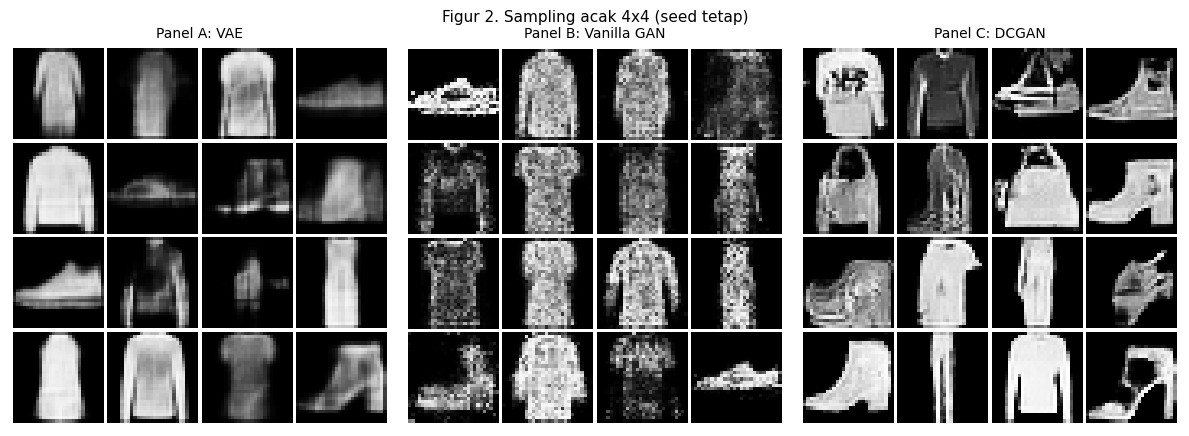

In [32]:
@torch.no_grad()
def _noise(n, dim, seed):
    g = torch.Generator(device=device).manual_seed(seed)
    return torch.randn(n, dim, device=device, generator=g)

@torch.no_grad()
def sample_vae(n, seed=SEED):
    vae.eval()
    return vae.decode(_noise(n, vae.z_dim, seed)).view(-1, *IMG_SHAPE)

@torch.no_grad()
def sample_gan(G, n, seed=SEED):
    G.eval()
    return from_minus1_1(G(_noise(n, Z_DIM_GAN, seed)))

SAMPLERS = {
    "VAE": sample_vae,
    "Vanilla GAN": lambda n, seed=SEED: sample_gan(G_van, n, seed),
    "DCGAN": lambda n, seed=SEED: sample_gan(G_dc, n, seed),
}

@torch.no_grad()
def measure_latency(fn, n_warmup=10, n_runs=50):
    for _ in range(n_warmup):
        fn()
    if device.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(n_runs):
        fn()
    if device.type == "cuda": torch.cuda.synchronize()
    return (time.time() - t0) / n_runs * 1000

LATENCY_MS = {name: measure_latency(lambda f=fn: f(64)) for name, fn in SAMPLERS.items()}
print("Latency inferensi per batch 64 sampel (ms):")
for k, v in LATENCY_MS.items():
    print(f"  {k:<12} {v:.2f}")


def plot_sample_grids(names, fname="fig2_random_samples.png"):
    fig, axes = plt.subplots(1, len(names), figsize=(4 * len(names), 4.4))
    for i, (ax, name) in enumerate(zip(np.atleast_1d(axes), names)):
        grid = make_grid(SAMPLERS[name](16).cpu(), nrow=4, padding=1, pad_value=1.0)
        ax.imshow(grid.permute(1, 2, 0).numpy(), vmin=0, vmax=1)
        ax.set_title(f"Panel {chr(65 + i)}: {name}", fontsize=10)
        ax.axis('off')
    fig.suptitle("Figur 2. Sampling acak 4x4 (seed tetap)", fontsize=11)
    plt.tight_layout()
    fig.savefig(FIG_DIR / fname, dpi=200, bbox_inches='tight')
    plt.show()

plot_sample_grids(["VAE", "Vanilla GAN", "DCGAN"])

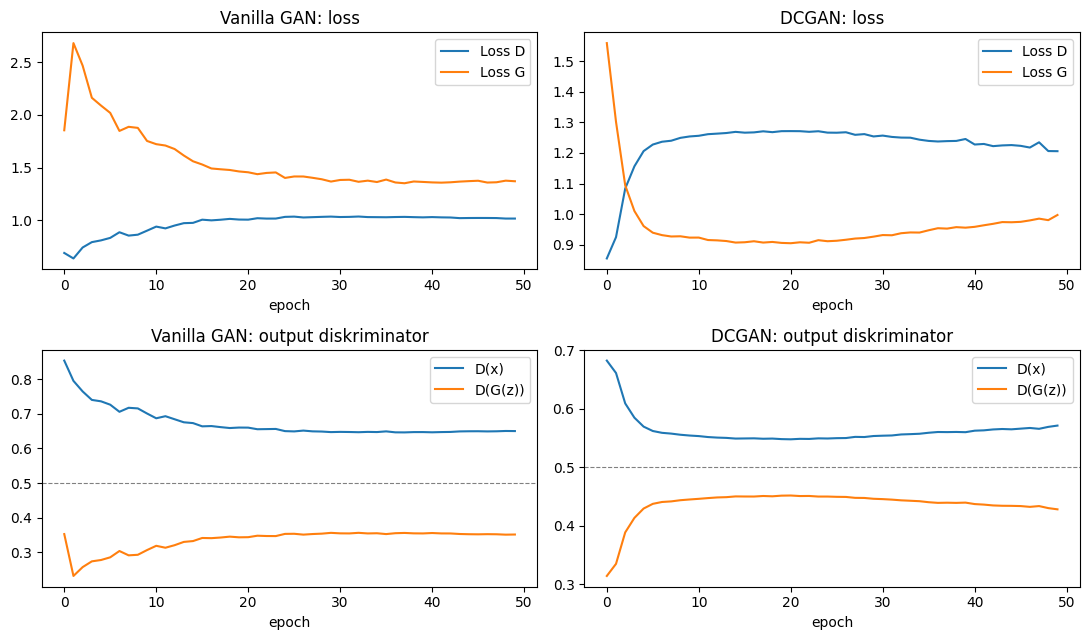

Sumber          jarak antar-sampel   kelas terwakili (>2%)
Data asli                   11.228                      10
VAE                          8.787                      10
Vanilla GAN                 10.649                      10
DCGAN                       11.484                      10

Sebaran kelas (indeks 0-9):
  Data asli    [0.13 0.1  0.1  0.1  0.1  0.1  0.09 0.09 0.1  0.09]
  VAE          [0.11 0.09 0.08 0.13 0.07 0.09 0.07 0.12 0.16 0.08]
  Vanilla GAN  [0.16 0.02 0.08 0.11 0.11 0.1  0.11 0.15 0.1  0.06]
  DCGAN        [0.11 0.12 0.1  0.09 0.11 0.09 0.07 0.09 0.11 0.11]


In [33]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
for col, (name, h) in enumerate([("Vanilla GAN", hist_gan), ("DCGAN", hist_dcgan)]):
    axes[0, col].plot(h["loss_D"], label="Loss D"); axes[0, col].plot(h["loss_G"], label="Loss G")
    axes[0, col].set_title(f"{name}: loss"); axes[0, col].set_xlabel("epoch"); axes[0, col].legend()
    axes[1, col].plot(h["D_real"], label="D(x)"); axes[1, col].plot(h["D_fake"], label="D(G(z))")
    axes[1, col].axhline(0.5, color='gray', ls='--', lw=0.8)
    axes[1, col].set_title(f"{name}: output diskriminator"); axes[1, col].set_xlabel("epoch"); axes[1, col].legend()
plt.tight_layout()
fig.savefig(FIG_DIR / "gan_training_curves.png", dpi=200, bbox_inches='tight')
plt.show()

@torch.no_grad()
def diversity_report(imgs01, n_cls=10):
    probs = F.softmax(mlp(imgs01.to(device)), 1)
    hist_cls = torch.bincount(probs.argmax(1), minlength=n_cls).float()
    share = (hist_cls / hist_cls.sum()).cpu().numpy()
    f = flat(imgs01.to(device))[:500]
    pairwise = torch.pdist(f).mean().item()
    return share, pairwise

real_imgs = torch.cat([x for x, _ in list(loaders['test'])[:6]])[:2000]
share_r, pd_r = diversity_report(real_imgs)
print(f"{'Sumber':<14}{'jarak antar-sampel':>20}{'kelas terwakili (>2%)':>24}")
print(f"{'Data asli':<14}{pd_r:>20.3f}{int((share_r > 0.02).sum()):>24}")
DIVERSITY = {"Data asli": {"pairwise": pd_r, "class_share": share_r.tolist()}}
for name in ["VAE", "Vanilla GAN", "DCGAN"]:
    sh, pdv = diversity_report(SAMPLERS[name](2000))
    DIVERSITY[name] = {"pairwise": pdv, "class_share": sh.tolist()}
    print(f"{name:<14}{pdv:>20.3f}{int((sh > 0.02).sum()):>24}")
print("\nSebaran kelas (indeks 0-9):")
for k, v in DIVERSITY.items():
    print(f"  {k:<12}", np.round(v["class_share"], 2))

Vanilla GAN
  conf kelas 1: 1.00 | conf kelas 9: 1.00
DCGAN
  conf kelas 1: 1.00 | conf kelas 9: 1.00


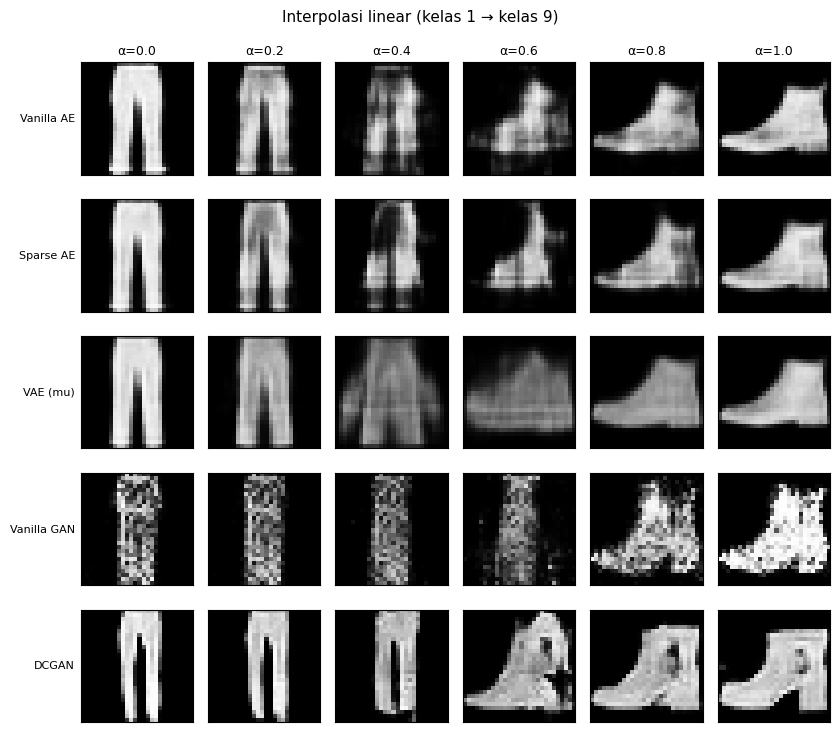

In [34]:
CLASS_A, CLASS_B = 1, 9
ALPHAS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

@torch.no_grad()
def pick_test_image(c):
    for x, y in loaders['test']:
        m = (y == c).nonzero()
        if len(m):
            return x[m[0, 0]].unsqueeze(0).to(device)

@torch.no_grad()
def pick_gan_latents(G, n=3000, seed=SEED):
    G.eval()
    z = _noise(n, Z_DIM_GAN, seed)
    probs = F.softmax(mlp(from_minus1_1(G(z))), 1)
    ia, ib = probs[:, CLASS_A].argmax(), probs[:, CLASS_B].argmax()
    print(f"  conf kelas {CLASS_A}: {probs[ia, CLASS_A]:.2f} | conf kelas {CLASS_B}: {probs[ib, CLASS_B]:.2f}")
    return z[ia:ia + 1], z[ib:ib + 1]

def lerp(za, zb):
    return torch.cat([(1 - a) * za + a * zb for a in ALPHAS])

xa, xb = pick_test_image(CLASS_A), pick_test_image(CLASS_B)
with torch.no_grad():
    rows = []
    for name, enc, dec in [("Vanilla AE", ae.encode, ae.dec), ("Sparse AE", sparse_ae.encode, sparse_ae.dec), ("VAE (mu)", lambda x: vae.encode(x)[0], vae.decode)]:
        rows.append((name, dec(lerp(enc(xa), enc(xb)))))
    for name, G in [("Vanilla GAN", G_van), ("DCGAN", G_dc)]:
        print(name)
        za, zb = pick_gan_latents(G)
        rows.append((name, from_minus1_1(G(lerp(za, zb)))))

fig, axes = plt.subplots(len(rows), len(ALPHAS), figsize=(8.5, 7.5))
for r, (label, imgs) in enumerate(rows):
    show_row(axes[r], to_img(imgs), label)
for j, a in enumerate(ALPHAS):
    axes[0][j].set_title(f"α={a:.1f}", fontsize=9)
fig.suptitle(f"Interpolasi linear (kelas {CLASS_A} → kelas {CLASS_B})", fontsize=11)
plt.tight_layout()
fig.savefig(FIG_DIR / "fig4_interpolation.png", dpi=200, bbox_inches='tight')
plt.show()

In [35]:
save_json({
    "vanilla_gan": {"epoch_time_mean": float(np.mean(hist_gan["epoch_time"])), "final_loss_D": hist_gan["loss_D"][-1], "final_loss_G": hist_gan["loss_G"][-1]},
    "dcgan": {"epoch_time_mean": float(np.mean(hist_dcgan["epoch_time"])), "final_loss_D": hist_dcgan["loss_D"][-1], "final_loss_G": hist_dcgan["loss_G"][-1]},
    "latency_ms_batch64": LATENCY_MS,
    "diversity": DIVERSITY,
}, RESULT_DIR / "gan_metrics.json")

In [36]:
import math, copy

T_DIFF = 1000
betas = torch.linspace(1e-4, 0.02, T_DIFF, device=device)
alphas = 1.0 - betas
alpha_bar = torch.cumprod(alphas, 0)
sqrt_ab = alpha_bar.sqrt()
sqrt_1m_ab = (1.0 - alpha_bar).sqrt()
sqrt_recip_alpha = (1.0 / alphas).sqrt()

def q_sample(x0, t, noise):
    return sqrt_ab[t].view(-1, 1, 1, 1) * x0 + sqrt_1m_ab[t].view(-1, 1, 1, 1) * noise

def timestep_embedding(t, dim):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
    args = t.float()[:, None] * freqs[None]
    return torch.cat([args.sin(), args.cos()], dim=-1)


class ResBlock(nn.Module):
    def __init__(self, cin, cout, tdim):
        super().__init__()
        self.n1 = nn.GroupNorm(8, cin);  self.c1 = nn.Conv2d(cin, cout, 3, 1, 1)
        self.t = nn.Linear(tdim, cout)
        self.n2 = nn.GroupNorm(8, cout); self.c2 = nn.Conv2d(cout, cout, 3, 1, 1)
        self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()

    def forward(self, x, te):
        h = self.c1(F.silu(self.n1(x)))
        h = h + self.t(te)[:, :, None, None]
        h = self.c2(F.silu(self.n2(h)))
        return h + self.skip(x)


class UNet(nn.Module):
    def __init__(self, c_in=C_IMG, base=64, tdim=256):
        super().__init__()
        self.tdim = tdim
        self.temb = nn.Sequential(nn.Linear(128, tdim), nn.SiLU(), nn.Linear(tdim, tdim))
        self.inc = nn.Conv2d(c_in, base, 3, 1, 1)
        self.enc1 = ResBlock(base, base, tdim)
        self.down1 = nn.Conv2d(base, base, 3, 2, 1)
        self.enc2 = ResBlock(base, base * 2, tdim)
        self.down2 = nn.Conv2d(base * 2, base * 2, 3, 2, 1)
        self.mid1 = ResBlock(base * 2, base * 4, tdim)
        self.mid2 = ResBlock(base * 4, base * 2, tdim)
        self.up2 = nn.ConvTranspose2d(base * 2, base * 2, 4, 2, 1)
        self.dec2 = ResBlock(base * 4, base * 2, tdim)
        self.up1 = nn.ConvTranspose2d(base * 2, base, 4, 2, 1)
        self.dec1 = ResBlock(base * 2, base, tdim)
        self.out = nn.Sequential(nn.GroupNorm(8, base), nn.SiLU(), nn.Conv2d(base, c_in, 3, 1, 1))

    def forward(self, x, t):
        te = self.temb(timestep_embedding(t, 128))
        h0 = self.inc(x)
        h1 = self.enc1(h0, te)
        h2 = self.enc2(self.down1(h1), te)
        m = self.mid2(self.mid1(self.down2(h2), te), te)
        u2 = self.dec2(torch.cat([self.up2(m), h2], 1), te)
        u1 = self.dec1(torch.cat([self.up1(u2), h1], 1), te)
        return self.out(u1)


@torch.no_grad()
def ema_update(ema, model, decay=0.999):
    for pe, pm in zip(ema.parameters(), model.parameters()):
        pe.mul_(decay).add_(pm.detach(), alpha=1 - decay)


set_seed(SEED)
unet = UNet().to(device)
ema_model = copy.deepcopy(unet).eval()
for p in ema_model.parameters():
    p.requires_grad = False
print(f"Parameter U-Net: {sum(p.numel() for p in unet.parameters()):,}")

Parameter U-Net: 3,170,689


In [37]:
def train_ddpm(model, ema, epochs=40, lr=2e-4, name="ddpm", save_every=5):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "val_loss": [], "epoch_time": []}
    start, path = 0, CKPT_DIR / f"{name}.pt"
    if path.exists():
        ck = torch.load(path, map_location=device)
        model.load_state_dict(ck["model"]); ema.load_state_dict(ck["ema"])
        opt.load_state_dict(ck["opt"]); hist, start = ck["history"], ck["epoch"]
        print(f"[resume] {name} dari epoch {start}")

    for ep in range(start + 1, epochs + 1):
        t0 = time.time(); model.train(); tot = n = 0
        for x, _ in loaders['train']:
            x = to_minus1_1(x).to(device); b = x.size(0)
            t = torch.randint(0, T_DIFF, (b,), device=device)
            noise = torch.randn_like(x)
            loss = F.mse_loss(model(q_sample(x, t, noise), t), noise)
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); ema_update(ema, model)
            tot += loss.item() * b; n += b
        model.eval(); vt = vn = 0
        with torch.no_grad():
            for x, _ in loaders['val']:
                x = to_minus1_1(x).to(device); b = x.size(0)
                t = torch.randint(0, T_DIFF, (b,), device=device)
                noise = torch.randn_like(x)
                vt += F.mse_loss(model(q_sample(x, t, noise), t), noise).item() * b; vn += b
        if device.type == "cuda":
            torch.cuda.synchronize()
        hist["train_loss"].append(tot / n); hist["val_loss"].append(vt / vn)
        hist["epoch_time"].append(time.time() - t0)
        print(f"Epoch {ep:02d} | train {tot/n:.5f} | val {vt/vn:.5f} | {hist['epoch_time'][-1]:.1f}s")
        if ep % save_every == 0 or ep == epochs:
            torch.save({"model": model.state_dict(), "ema": ema.state_dict(), "opt": opt.state_dict(), "epoch": ep, "history": hist}, path)
            save_json(hist, RESULT_DIR / f"{name}_history.json")
    return hist

hist_ddpm = train_ddpm(unet, ema_model, epochs=40)

Epoch 01 | train 0.07974 | val 0.05465 | 50.5s
Epoch 02 | train 0.05035 | val 0.04822 | 48.4s
Epoch 03 | train 0.04547 | val 0.04532 | 49.6s
Epoch 04 | train 0.04350 | val 0.04452 | 49.3s
Epoch 05 | train 0.04216 | val 0.04219 | 48.4s
Epoch 06 | train 0.04105 | val 0.04167 | 47.9s
Epoch 07 | train 0.04054 | val 0.04234 | 47.7s
Epoch 08 | train 0.04037 | val 0.04097 | 47.9s
Epoch 09 | train 0.04000 | val 0.03905 | 47.7s
Epoch 10 | train 0.03880 | val 0.04048 | 47.9s
Epoch 11 | train 0.03927 | val 0.03941 | 48.0s
Epoch 12 | train 0.03869 | val 0.03896 | 47.9s
Epoch 13 | train 0.03810 | val 0.03711 | 48.2s
Epoch 14 | train 0.03825 | val 0.03795 | 48.1s
Epoch 15 | train 0.03775 | val 0.03896 | 47.9s
Epoch 16 | train 0.03821 | val 0.03776 | 48.0s
Epoch 17 | train 0.03755 | val 0.03845 | 47.8s
Epoch 18 | train 0.03755 | val 0.03663 | 48.2s
Epoch 19 | train 0.03786 | val 0.03848 | 48.0s
Epoch 20 | train 0.03789 | val 0.03727 | 48.0s
Epoch 21 | train 0.03750 | val 0.03698 | 48.2s
Epoch 22 | tr

Latency inferensi per batch 64 sampel (ms):
  VAE                0.23
  Vanilla GAN        0.34
  DCGAN              4.04
  DDPM           18715.47

DDPM / DCGAN = 4627x lebih lambat


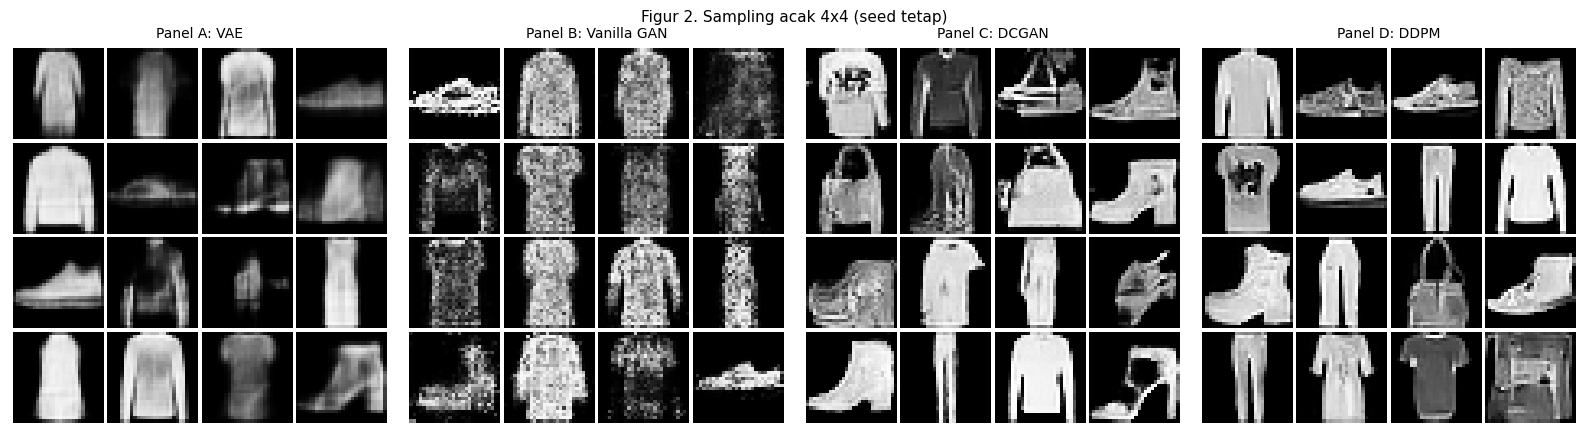

In [38]:
@torch.no_grad()
def ddpm_sample(model, n, seed=SEED, save_at=None):
    model.eval()
    g = torch.Generator(device=device).manual_seed(seed)
    x = torch.randn(n, *IMG_SHAPE, device=device, generator=g)
    traj = {T_DIFF: x.clone()} if save_at is not None else {}
    for t in reversed(range(T_DIFF)):
        tt = torch.full((n,), t, device=device, dtype=torch.long)
        eps = model(x, tt)
        mean = sqrt_recip_alpha[t] * (x - betas[t] / sqrt_1m_ab[t] * eps)
        if t > 0:
            x = mean + betas[t].sqrt() * torch.randn(x.shape, device=device, generator=g)
        else:
            x = mean
        if save_at is not None and t in save_at:
            traj[t] = x.clone()
    return x.clamp(-1, 1), traj

SAMPLERS["DDPM"] = lambda n, seed=SEED: from_minus1_1(ddpm_sample(ema_model, n, seed)[0])

LATENCY_MS["DDPM"] = measure_latency(lambda: SAMPLERS["DDPM"](64), n_warmup=1, n_runs=3)
print("Latency inferensi per batch 64 sampel (ms):")
for k, v in LATENCY_MS.items():
    print(f"  {k:<12} {v:>10.2f}")
print(f"\nDDPM / DCGAN = {LATENCY_MS['DDPM'] / LATENCY_MS['DCGAN']:.0f}x lebih lambat")

plot_sample_grids(["VAE", "Vanilla GAN", "DCGAN", "DDPM"])

In [39]:
import torch_fidelity

class UInt8Images(torch.utils.data.Dataset):
    def __init__(self, imgs01):
        x = (imgs01 * 255).round().clamp(0, 255).to(torch.uint8)
        self.x = x.repeat(1, 3, 1, 1) if x.size(1) == 1 else x
    def __len__(self):
        return len(self.x)
    def __getitem__(self, i):
        return self.x[i]

def fid_score(a01, b01):
    m = torch_fidelity.calculate_metrics(
        input1=UInt8Images(a01), input2=UInt8Images(b01),
        cuda=(device.type == "cuda"), isc=False, fid=True, kid=False,
        batch_size=128, verbose=False)
    return m["frechet_inception_distance"]

def generate_many(name, n, bs=500):
    return torch.cat([SAMPLERS[name](min(bs, n - i), seed=SEED + i).cpu() for i in range(0, n, bs)])

N_FID = 5000
real_test = torch.cat([x for x, _ in loaders['test']])
real_val = torch.cat([x for x, _ in loaders['val']])[:N_FID]

FID = {"Real (val) vs test [batas bawah]": fid_score(real_val, real_test)}
print(f"{'Real (val) vs test':<22} FID = {FID['Real (val) vs test [batas bawah]']:.2f}")
for name in ["VAE", "Vanilla GAN", "DCGAN", "DDPM"]:
    path = RESULT_DIR / f"gen_{name.replace(' ', '_')}_{N_FID}.pt"
    if path.exists():
        g = torch.load(path).float() / 255
    else:
        t0 = time.time()
        g = generate_many(name, N_FID)
        torch.save((g * 255).round().to(torch.uint8), path)
        print(f"  ({name}: generate {N_FID} sampel {time.time()-t0:.0f}s)")
    FID[name] = fid_score(g, real_test)
    print(f"{name:<22} FID = {FID[name]:.2f}")

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation mig

Real (val) vs test     FID = 4.42
  (VAE: generate 5000 sampel 0s)
VAE                    FID = 86.02
  (Vanilla GAN: generate 5000 sampel 0s)
Vanilla GAN            FID = 134.56
  (DCGAN: generate 5000 sampel 1s)
DCGAN                  FID = 18.37
  (DDPM: generate 5000 sampel 1409s)
DDPM                   FID = 9.33


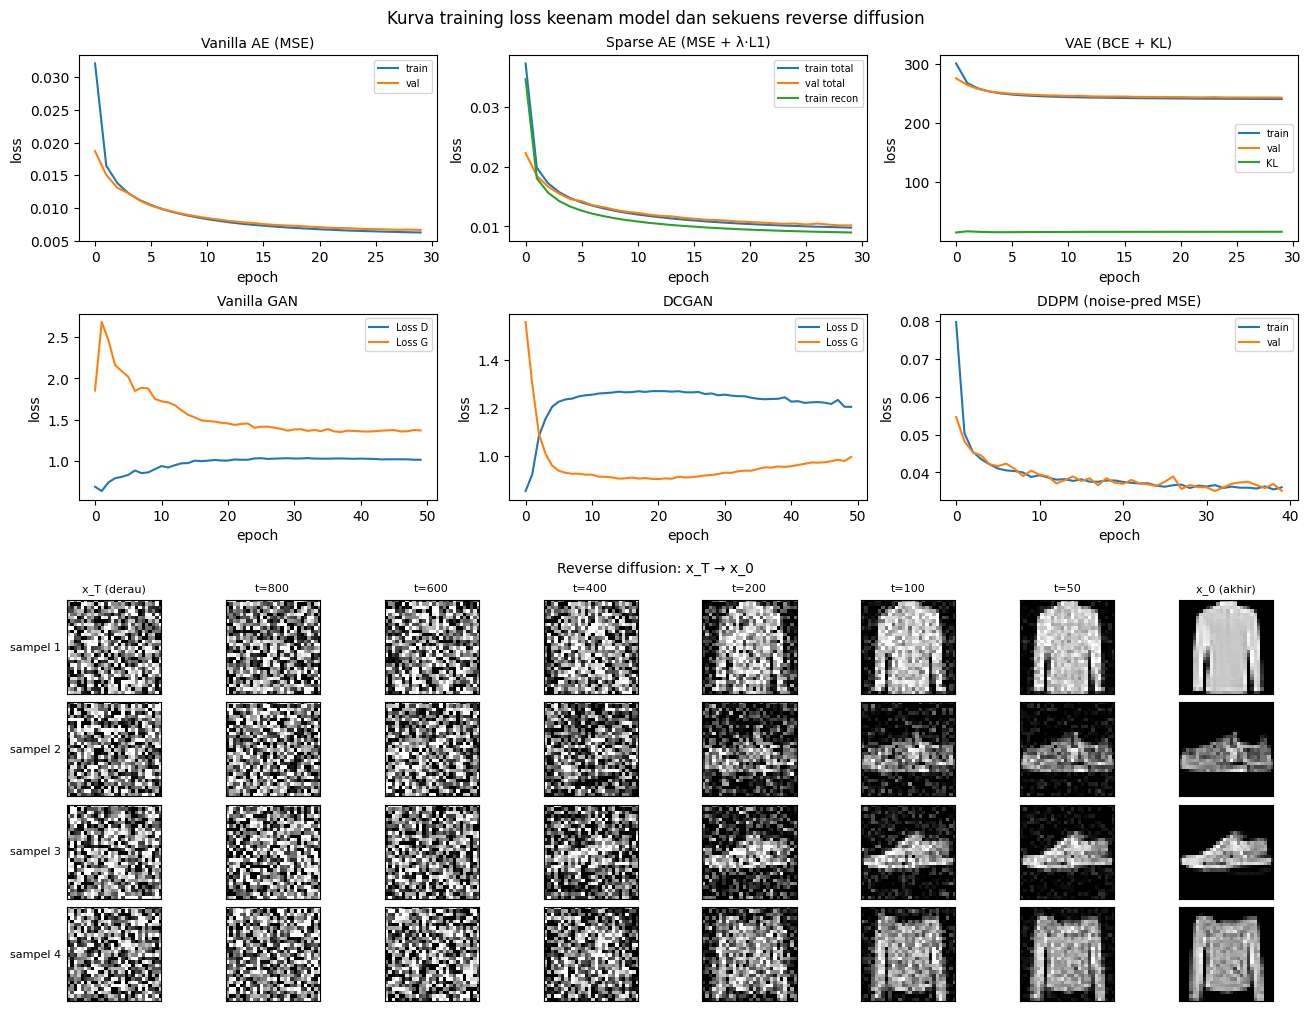

In [40]:
SAVE_AT = [800, 600, 400, 200, 100, 50, 0]
x_final, traj = ddpm_sample(ema_model, 4, seed=SEED, save_at=set(SAVE_AT))
snap_keys = [T_DIFF] + SAVE_AT

fig = plt.figure(figsize=(13, 10), constrained_layout=True)
top, bot = fig.subfigures(2, 1, height_ratios=[1.15, 1])

ax = top.subplots(2, 3)
def curves(a, title, series, ylabel="loss"):
    for lab, vals in series:
        a.plot(vals, label=lab)
    a.set_title(title, fontsize=10); a.set_xlabel("epoch"); a.set_ylabel(ylabel); a.legend(fontsize=7)

curves(ax[0, 0], "Vanilla AE (MSE)", [("train", hist_vae64["train_loss"]), ("val", hist_vae64["val_loss"])])
curves(ax[0, 1], f"Sparse AE (MSE + λ·L1)", [("train total", hist_sparse["train_loss"]), ("val total", hist_sparse["val_loss"]), ("train recon", hist_sparse["train_recon"])])
curves(ax[0, 2], "VAE (BCE + KL)", [("train", hist_vae["train_loss"]), ("val", hist_vae["val_loss"]), ("KL", hist_vae["train_kl"])])
curves(ax[1, 0], "Vanilla GAN", [("Loss D", hist_gan["loss_D"]), ("Loss G", hist_gan["loss_G"])])
curves(ax[1, 1], "DCGAN", [("Loss D", hist_dcgan["loss_D"]), ("Loss G", hist_dcgan["loss_G"])])
curves(ax[1, 2], "DDPM (noise-pred MSE)", [("train", hist_ddpm["train_loss"]), ("val", hist_ddpm["val_loss"])])

axb = bot.subplots(4, len(snap_keys))
for r in range(4):
    imgs = torch.stack([from_minus1_1(traj[k][r]) for k in snap_keys]).cpu()
    show_row(axb[r], imgs, f"sampel {r + 1}")
for j, k in enumerate(snap_keys):
    axb[0][j].set_title("x_T (derau)" if k == T_DIFF else ("x_0 (akhir)" if k == 0 else f"t={k}"), fontsize=8)
bot.suptitle("Reverse diffusion: x_T → x_0", fontsize=10)

fig.suptitle("Kurva training loss keenam model dan sekuens reverse diffusion", fontsize=12)
fig.savefig(FIG_DIR / "fig5_training_and_reverse.png", dpi=200, bbox_inches='tight')
plt.show()

In [41]:
hist_map = {"Vanilla AE": hist_vae64, "Sparse AE": hist_sparse, "VAE": hist_vae, "Vanilla GAN": hist_gan, "DCGAN": hist_dcgan, "DDPM": hist_ddpm}
recon_map = {"Vanilla AE": res_ae, "Sparse AE": res_sp, "VAE": res_vae}

print(f"{'Model':<13}{'MSE':>9}{'PSNR':>8}{'SSIM':>8}{'FID':>9}{'s/epoch':>10}{'latency 64 (ms)':>17}")
final = {}
for name, h in hist_map.items():
    r = recon_map.get(name)
    row = {"mse": r["mse"] if r else None, "psnr": r["psnr"] if r else None, "ssim": r["ssim"] if r else None,
           "fid": FID.get(name), "epoch_time": float(np.mean(h["epoch_time"])),
           "latency_ms": LATENCY_MS.get(name)}
    final[name] = row
    f = lambda v, p: "-" if v is None else f"{v:.{p}f}"
    print(f"{name:<13}{f(row['mse'],5):>9}{f(row['psnr'],2):>8}{f(row['ssim'],3):>8} {f(row['fid'],1):>9}{row['epoch_time']:>10.1f}{f(row['latency_ms'],1):>17}")

save_json({"models": final, "fid_reference": FID["Real (val) vs test [batas bawah]"],
           "n_fid": N_FID, "T_diffusion": T_DIFF}, RESULT_DIR / "final_results.json")

Model              MSE    PSNR    SSIM      FID   s/epoch  latency 64 (ms)
Vanilla AE     0.00653   23.01   0.829         -       8.1                -
Sparse AE      0.00920   21.40   0.772         -       9.2                -
VAE            0.01298   19.73   0.714      86.0       8.5              0.2
Vanilla GAN          -       -       -     134.6       9.5              0.3
DCGAN                -       -       -      18.4      14.8              4.0
DDPM                 -       -       -       9.3      48.1          18715.5
